In [ ]:
 # Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
)

In [ ]:
# Models Imported
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [ ]:
# Load dataset
stroke_dataset = pd.read_csv("stroke.csv")

In [ ]:
# Define features and target
X= stroke_dataset.drop('Diagnosis Encoded', axis=1)
y = stroke_dataset['Diagnosis Encoded']

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
# Standardize numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:
# Define models for comparison
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel='rbf', probability=True),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', use_label_encoder=False, random_state=42)
}


In [ ]:
# Store results for each model
results = []


In [ ]:
# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
 # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
# Append results to summary table
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })



In [ ]:
 # Create and display summary table
summary = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
print("✅ Model Comparison Summary:")
print(summary)


✅ Model Comparison Summary:
                 Model  Accuracy  Precision  Recall  F1-Score
5              XGBoost    0.9492   0.953188  0.9448  0.948975
4        Random Forest    0.9436   0.950447  0.9360  0.943168
3        Decision Tree    0.9000   0.903226  0.8960  0.899598
0  Logistic Regression    0.6424   0.642173  0.6432  0.642686
2                  SVM    0.6412   0.639968  0.6456  0.642772
1                  KNN    0.5448   0.544872  0.5440  0.544436


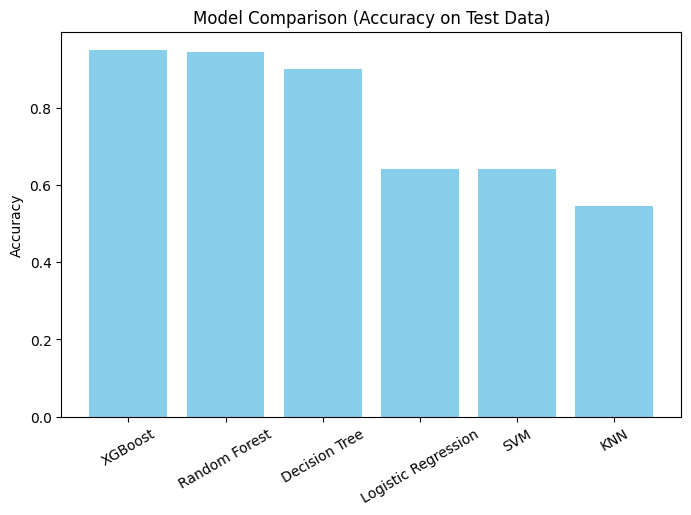

In [ ]:

# Visualize model comparison
plt.figure(figsize=(8,5))
plt.bar(summary['Model'], summary['Accuracy'], color='skyblue')
plt.title('Model Comparison (Accuracy on Test Data)')
plt.ylabel('Accuracy')
plt.xticks(rotation=30)
plt.show()